In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score, recall_score, balanced_accuracy_score, precision_score, root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import LinearSegmentedColormap
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression

# Logistic Regression

In [2]:
# logistic uses the same dataset as NaiveBayes: same file, same split, same features
logistic_regression_labeled = pd.read_csv("../../data/clean/naivebayes/nb_labeled.csv")
logistic_regression_labeled.head(8).T.round(2)

,0,1,2,3,4,5,6,7
participant_id,P1,P1,P1,P1,P1,P1,P1,P1
calendarDate,2025-07-13,2025-08-18,2025-08-19,2025-08-20,2025-08-21,2025-08-22,2025-08-23,2025-08-25
cohort,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03
durationInMs,28620000.0,28500000.0,26520000.0,25500000.0,23460000.0,30180000.0,29160000.0,27720000.0
deepSleepDurationInMs,3480000.0,5160000.0,2160000.0,4620000.0,2820000.0,2880000.0,2160000.0,5220000.0
lightSleepDurationInMs,20160000.0,20100000.0,20040000.0,16980000.0,19620000.0,23400000.0,24780000.0,16380000.0
remSleepInMs,4980000.0,3240000.0,4320000.0,3900000.0,1020000.0,3900000.0,2220000.0,6120000.0
awakeDurationInMs,360000.0,780000.0,180000.0,0.0,900000.0,3060000.0,360000.0,0.0
overallSleepScore,79.0,79.0,79.0,80.0,48.0,55.0,47.0,74.0
breathsPerMinute_mean,19.0785,19.163504,18.843708,17.915741,18.371798,18.5172,19.749706,18.339479


In [3]:
y_logistic = logistic_regression_labeled["low_recovery"]
groups = logistic_regression_labeled["participant_id"]

features_to_remove = [
    "participant_id",
    "cohort",
    "calendarDate",
    "low_recovery"
]

X_logistic = logistic_regression_labeled.drop(columns = features_to_remove)

print(y_logistic.shape,X_logistic.shape)


(18728,) (18728, 20)


In [4]:
# Train/test split pattern adapted from the scikit-learn StratifiedGroupKFold documentation example
# modified to use a single split and this project's columns.

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx_log, test_idx_log = next(sgkf.split(X_logistic,y_logistic,groups = groups))

X_log_train, X_log_test = X_logistic.iloc[train_idx_log], X_logistic.iloc[test_idx_log]
y_log_train, y_log_test = y_logistic.iloc[train_idx_log], y_logistic.iloc[test_idx_log]

print(f"Train size: {len(train_idx_log)}")
print(f"Test size: {len(test_idx_log)}")

Train size: 15003
Test size: 3725


In [5]:
#code to reduce features to the below 75% correlation threshold
correlated_features_to_remove = [
    "lightSleepDurationInMs",
    "breathsPerMinute_max",
    "minHeartRateInBeatsPerMinute"
]

X_log_train = X_log_train.drop(columns = correlated_features_to_remove, errors = "ignore")
X_log_test = X_log_test.drop(columns = correlated_features_to_remove, errors = "ignore")

## Verifying test/train split numbers

In [6]:
print(f"People in both sets: {len(set(groups.iloc[X_log_train.index]) & set(groups.iloc[test_idx_log]))}")
print(f"People in total: {len(set(groups.iloc[train_idx_log]) | set(groups.iloc[test_idx_log]))}")
print(f"{len(groups.iloc[train_idx_log])} + {len(groups.iloc[test_idx_log])} = {len(groups.iloc[train_idx_log]) + len(groups.iloc[test_idx_log])}")

People in both sets: 0
People in total: 98
15003 + 3725 = 18728


In [7]:
print(f"Training set low-recovery count: {y_log_train.sum()}")
print(f"Testing set low-recovery count: {y_log_test.sum()}")
print(f"Training: {groups.iloc[train_idx_log].nunique()} people, {len(train_idx_log)} nights, {(y_log_train.mean()*100).round(2)}% low recovery")
print(f"Testing: {groups.iloc[test_idx_log].nunique()} people, {len(test_idx_log)} nights, {(y_log_test.mean()*100).round(2)}% low recovery")
print("With training and test split such that there are 79 + 19 = 98 (100%) people and 15003 + 3725 = 18728 (100%) nights, " \
"\n we can conclude that no person appears in both sets")

print(len(test_idx_log)-y_log_test.sum())

Training set low-recovery count: 1539
Testing set low-recovery count: 381
Training: 79 people, 15003 nights, 10.26% low recovery
Testing: 19 people, 3725 nights, 10.23% low recovery
With training and test split such that there are 79 + 19 = 98 (100%) people and 15003 + 3725 = 18728 (100%) nights, 
 we can conclude that no person appears in both sets
3344


## Logistic Regression Testing

In [8]:
lr = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000, class_weight= "balanced"))
lr.fit(X_log_train, y_log_train)
coef_df = pd.DataFrame({
    'Feature': X_log_train.columns,
    'Coefficient': lr.steps[-1][1].coef_[0]
}).sort_values('Coefficient', ascending=False)

print(coef_df.to_string(index=False))

predictions = lr.predict(X_log_test)
f1_LR = np.round(f1_score(y_log_test,predictions),3)
print("\nF1 score:", f1_LR)

                         Feature  Coefficient
           deepSleepDurationInMs     0.322979
           breathsPerMinute_mean     0.251506
            breathsPerMinute_min     0.247677
   vigorousIntensityDurationInMs     0.230533
      averageStressInStressLevel     0.222626
                           steps     0.207152
                    durationInMs     0.200042
                    remSleepInMs     0.178375
    maxHeartRateInBeatsPerMinute     0.138998
            breathsPerMinute_std     0.117931
   moderateIntensityDurationInMs     0.077438
                 bmrKilocalories    -0.025619
          maxStressInStressLevel    -0.085294
restingHeartRateInBeatsPerMinute    -0.123877
               awakeDurationInMs    -0.195031
              activeKilocalories    -0.304361
               overallSleepScore    -1.406463

F1 score: 0.426


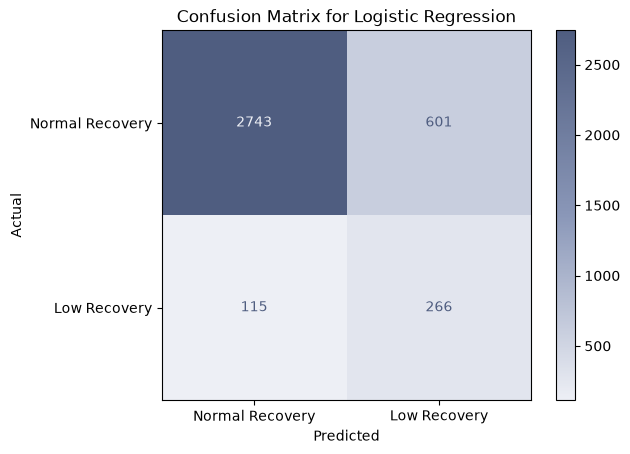

In [9]:
# code adapted from inclass notebook
# Generating the confusion matrix


nb_cmap = LinearSegmentedColormap.from_list("site_diverging", ["#EDEFF5", "#8A97B8", "#4F5D80"]) #establish suite of theme colors
cm = confusion_matrix(y_log_test, predictions)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal Recovery","Low Recovery"])
disp.plot(cmap = nb_cmap)
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
disp.ax_.set_title('Confusion Matrix for Logistic Regression');
plt.savefig("../../images/regression/logistic_confusion_matrix.png", dpi=150, bbox_inches="tight")

In [10]:
# Accuracy, F1 Score and Recall Score

accuracy = np.round(accuracy_score(y_log_test, predictions),3)

# accuracy = (TP + TN)/ total  -- measures the overall correctness aka how many predictions 
# were correct 


f1 = np.round(f1_score(y_log_test, predictions),3)

# 2 x (Precision x Recall) / (Precision + Recall) -- balances precision and recall and is useful when you care about both false positive and false negatives and also when your data is imbalanced 

recall = np.round(recall_score(y_log_test, predictions),3)
bas = np.round(balanced_accuracy_score(y_log_test, predictions),3)
ps = np.round(precision_score(y_log_test, predictions),3)
baseline = np.round(1 - y_log_test.mean(),3)

# TP/ (TP + FN ) -- Also called sensitivity or TPR (true positive rate) and this measures how well the model catches the positive class and this is important in cases like disease detection, fraud etc where missing positive is COSTLY!!!

print(f'Accuracy: {accuracy}')
print(f'F1 Score: {f1}')
print(f'Recall Score: {recall}')
print(f'Balanced Accuracy Score: {bas}')
print(f'Precision Score: {ps}')
print(f'Baseline Accuracy if model predicts "normal recovery" for every observation: {baseline}')

Accuracy: 0.808
F1 Score: 0.426
Recall Score: 0.698
Balanced Accuracy Score: 0.759
Precision Score: 0.307
Baseline Accuracy if model predicts "normal recovery" for every observation: 0.898


# Linear Regression

In [11]:
# linear regression is the same as logistic except it needs the HRV ratio column readded for prediction means
linear_regression_labeled = pd.read_csv("../../data/clean/regression/regression_labeled.csv")
linear_regression_labeled.head(8).T.round(2)

,0,1,2,3,4,5,6,7
participant_id,P1,P1,P1,P1,P1,P1,P1,P1
calendarDate,2025-07-13,2025-08-18,2025-08-19,2025-08-20,2025-08-21,2025-08-22,2025-08-23,2025-08-25
cohort,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03
durationInMs,28620000.0,28500000.0,26520000.0,25500000.0,23460000.0,30180000.0,29160000.0,27720000.0
deepSleepDurationInMs,3480000.0,5160000.0,2160000.0,4620000.0,2820000.0,2880000.0,2160000.0,5220000.0
lightSleepDurationInMs,20160000.0,20100000.0,20040000.0,16980000.0,19620000.0,23400000.0,24780000.0,16380000.0
remSleepInMs,4980000.0,3240000.0,4320000.0,3900000.0,1020000.0,3900000.0,2220000.0,6120000.0
awakeDurationInMs,360000.0,780000.0,180000.0,0.0,900000.0,3060000.0,360000.0,0.0
overallSleepScore,79.0,79.0,79.0,80.0,48.0,55.0,47.0,74.0
breathsPerMinute_mean,19.0785,19.163504,18.843708,17.915741,18.371798,18.5172,19.749706,18.339479


In [12]:
y_linear = linear_regression_labeled["hrv_ratio"]
groups = linear_regression_labeled["participant_id"]

features_to_remove = [
    "participant_id",
    "cohort",
    "calendarDate",
    "low_recovery",
    "hrv_ratio"
]

X_linear = linear_regression_labeled.drop(columns = features_to_remove)


print(y_linear.shape,X_linear.shape)

(18728,) (18728, 20)


In [13]:
# Train/test split pattern adapted from the scikit-learn StratifiedGroupKFold documentation example
# modified to use a single split and this project's columns.
# Split is stratified on low_recovery (not the continuous target) so linear gets the exact same people as logistic

sgkf_lin = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx_lin, test_idx_lin = next(sgkf_lin.split(X_linear, linear_regression_labeled["low_recovery"], groups = groups))

X_lin_train, X_lin_test = X_linear.iloc[train_idx_lin], X_linear.iloc[test_idx_lin]
y_lin_train, y_lin_test = y_linear.iloc[train_idx_lin], y_linear.iloc[test_idx_lin]

print(f"Train size: {len(train_idx_lin)}")
print(f"Test size: {len(test_idx_lin)}")

Train size: 15003
Test size: 3725


In [14]:
#code to reduce features to the below 75% correlation threshold

X_lin_train = X_lin_train.drop(columns = correlated_features_to_remove, errors = "ignore")
X_lin_test = X_lin_test.drop(columns = correlated_features_to_remove, errors = "ignore")

pd.concat([X_lin_train,y_linear.iloc[train_idx_lin]], axis = 1).to_csv("../../data/clean/regression/linear_regression_train.csv", index = False)
pd.concat([X_lin_test,y_linear.iloc[test_idx_lin]], axis = 1).to_csv("../../data/clean/regression/linear_regression_test.csv", index = False)


In [15]:
print(f"People in both sets: {len(set(groups.iloc[X_lin_train.index]) & set(groups.iloc[test_idx_lin]))}")
print(f"People in total: {len(set(groups.iloc[train_idx_lin]) | set(groups.iloc[test_idx_lin]))}")
print(f"{len(groups.iloc[train_idx_lin])} + {len(groups.iloc[test_idx_lin])} = {len(groups.iloc[train_idx_lin]) + len(groups.iloc[test_idx_lin])}")

People in both sets: 0
People in total: 98
15003 + 3725 = 18728


In [16]:
low_rec_lin = linear_regression_labeled["low_recovery"]

print(f"Training set low-recovery count: {low_rec_lin.iloc[train_idx_lin].sum()}")
print(f"Testing set low-recovery count: {low_rec_lin.iloc[test_idx_lin].sum()}")
print(f"Training: {groups.iloc[train_idx_lin].nunique()} people, {len(train_idx_lin)} nights, {(low_rec_lin.iloc[train_idx_lin].mean()*100).round(2)}% low recovery")
print(f"Testing: {groups.iloc[test_idx_lin].nunique()} people, {len(test_idx_lin)} nights, {(low_rec_lin.iloc[test_idx_lin].mean()*100).round(2)}% low recovery")
print("With training and test split such that there are 79 + 19 = 98 (100%) people and 15003 + 3725 = 18728 (100%) nights, " \
"\n we can conclude that no person appears in both sets")

Training set low-recovery count: 1539
Testing set low-recovery count: 381
Training: 79 people, 15003 nights, 10.26% low recovery
Testing: 19 people, 3725 nights, 10.23% low recovery
With training and test split such that there are 79 + 19 = 98 (100%) people and 15003 + 3725 = 18728 (100%) nights, 
 we can conclude that no person appears in both sets


In [17]:
linear_regression = make_pipeline(StandardScaler(), LinearRegression())
linear_regression.fit(X_lin_train, y_lin_train)
coef_df_lin = pd.DataFrame({
    'Feature': X_lin_train.columns,
    'Coefficient': linear_regression.steps[-1][1].coef_
}).sort_values('Coefficient', ascending=False)

print(coef_df_lin.to_string(index=False))

predictions_lin = linear_regression.predict(X_lin_test)
rmse = np.round(root_mean_squared_error(y_lin_test, predictions_lin),3)
mae = np.round(mean_absolute_error(y_lin_test, predictions_lin),3)
r2 = np.round(r2_score(y_lin_test, predictions_lin),3)
print(f"The Root Mean Squared Error is {rmse}\nThe Mean Absolute Error is {mae}\nThe R^2 Score is {r2}")

                         Feature  Coefficient
               overallSleepScore     0.087308
              activeKilocalories     0.018387
               awakeDurationInMs     0.014968
            breathsPerMinute_std     0.011050
                 bmrKilocalories     0.009133
restingHeartRateInBeatsPerMinute     0.008988
          maxStressInStressLevel     0.003905
   moderateIntensityDurationInMs    -0.000402
    maxHeartRateInBeatsPerMinute    -0.004832
            breathsPerMinute_min    -0.011441
                    remSleepInMs    -0.013906
   vigorousIntensityDurationInMs    -0.015746
                           steps    -0.015828
           deepSleepDurationInMs    -0.017522
      averageStressInStressLevel    -0.018484
           breathsPerMinute_mean    -0.018684
                    durationInMs    -0.021365
The Root Mean Squared Error is 0.159
The Mean Absolute Error is 0.119
The R^2 Score is 0.167


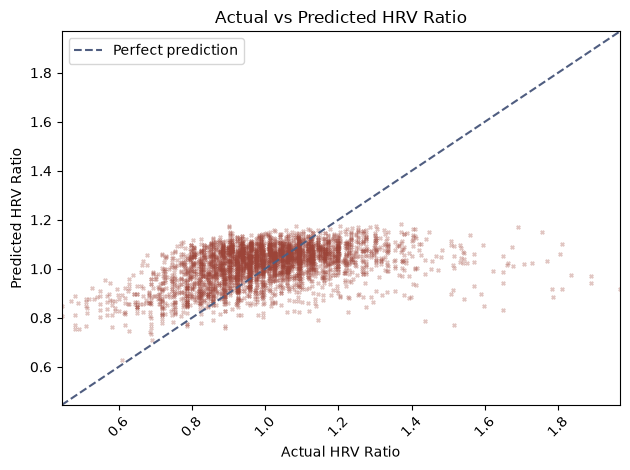

In [18]:
fig, ax = plt.subplots()
ax.scatter(y_lin_test, predictions_lin, color="#9C4438",s=6,  alpha=0.3, marker = "x")
ax.set_title("Actual vs Predicted HRV Ratio")
ax.set_ylabel("Predicted HRV Ratio")
ax.set_xlabel("Actual HRV Ratio")
low = min(y_lin_test.min(), predictions_lin.min())
high = max(y_lin_test.max(), predictions_lin.max())
ax.plot([low, high], [low, high], color="#4F5D80", linestyle="--", label="Perfect prediction")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.legend()
plt.xticks(rotation = 45)
plt.tight_layout()
plt.savefig("../../images/regression/actual_vs_predicted_hrv_ratio.png",dpi=150, bbox_inches="tight")
plt.show()
plt.close()